# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

          liczba_brakow  odsetek_brakow
Cabin               687       77.104377
Age                 177       19.865320
Embarked              2        0.224467


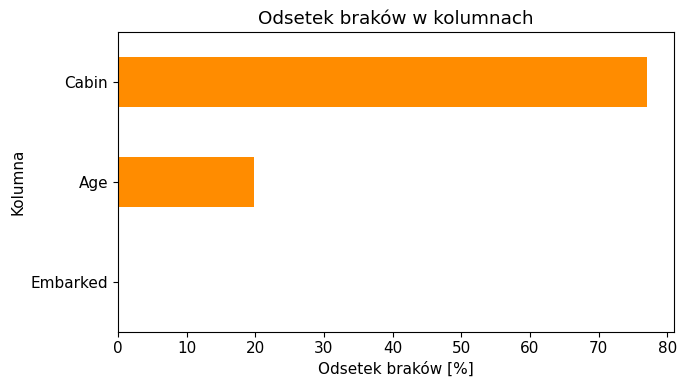

In [18]:
braki_liczba = titanic.isna().sum()
braki_odsetek = titanic.isna().mean() * 100

tabela_brakow = pd.DataFrame({
    'liczba_brakow': braki_liczba,
    'odsetek_brakow': braki_odsetek
})
tabela_brakow = tabela_brakow[tabela_brakow['liczba_brakow'] > 0].sort_values(by='liczba_brakow', ascending=False)
print(tabela_brakow)

plt.figure(figsize=(7, 4))
tabela_brakow['odsetek_brakow'].sort_values().plot.barh(color='darkorange')
plt.title('Odsetek braków w kolumnach')
plt.xlabel('Odsetek braków [%]')
plt.ylabel('Kolumna')
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?


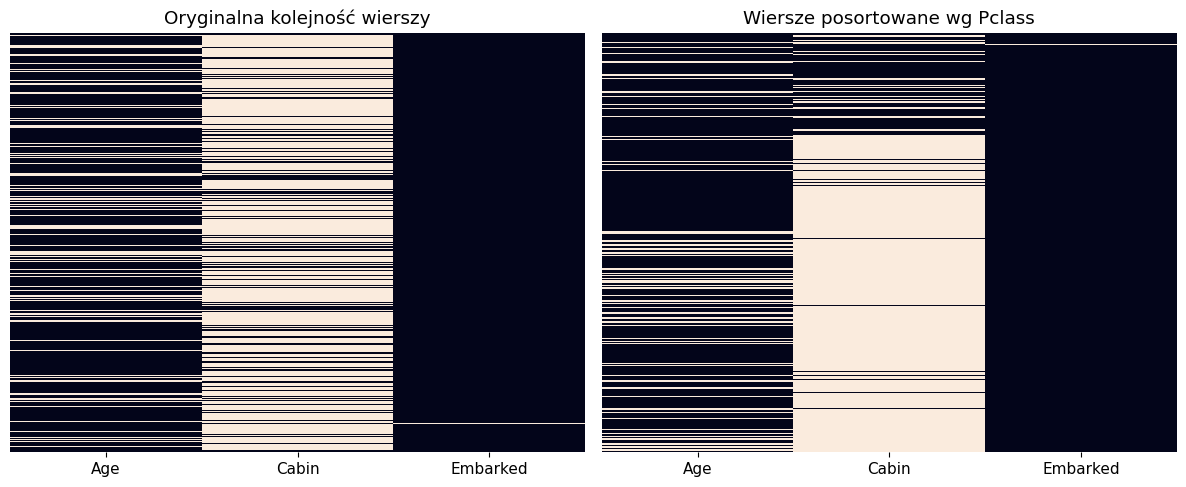

In [19]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=axes[0], yticklabels=False)
axes[0].set_title("Oryginalna kolejność wierszy")

kolejnosc = titanic.sort_values("Pclass").index
sns.heatmap(titanic.loc[kolejnosc, kolumny].isna(), cbar=False, ax=axes[1], yticklabels=False)
axes[1].set_title("Wiersze posortowane wg Pclass")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Po posortowaniu na drugim wykresie widać jak braki rozkładają się dla poszczególnych klas, a w pierwszym jedynie po kolejności występowania

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64
Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64
Wiek znany    40.616246
Brak wieku    29.378531
Name: Survived, dtype: float64


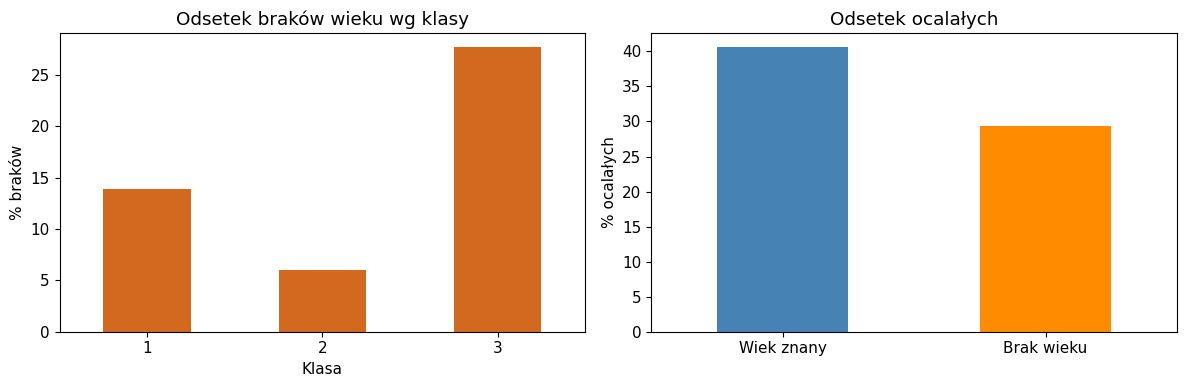

In [20]:
brak_wieku = titanic["Age"].isna()

braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100

print(braki_klasa)
print(braki_plec)

ocalali_porownanie = titanic.groupby(brak_wieku)["Survived"].mean() * 100
ocalali_porownanie.index = ["Wiek znany", "Brak wieku"]
print(ocalali_porownanie)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

braki_klasa.plot.bar(ax=axes[0], color='chocolate')
axes[0].set_title("Odsetek braków wieku wg klasy")
axes[0].set_xlabel("Klasa")
axes[0].set_ylabel("% braków")
axes[0].tick_params(axis='x', rotation=0)

ocalali_porownanie.plot.bar(ax=axes[1], color=['steelblue', 'darkorange'])
axes[1].set_title("Odsetek ocalałych")
axes[1].set_ylabel("% ocalałych")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Braki wieku nie są MCAR, brakuje losowości. Jeżeli usunełoby się osoby bez wieku to odsetek ogólny ocalałych byłby sztucznie zawyżony, a odsetek pasażerów 3 klasy byłby również zaburzony.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [21]:
warianty = {
    "bez zmian": titanic,
    "dropna(subset=['Embarked'])": titanic.dropna(subset=["Embarked"]),
    "dropna(subset=['Age'])": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna()
}

podsumowanie = []
for nazwa, df_wariant in warianty.items():
    podsumowanie.append({
        "wariant": nazwa,
        "liczba wierszy": len(df_wariant),
        "odsetek ocalałych": f"{df_wariant['Survived'].mean() * 100:.1f}%",
        "odsetek pasażerów 1. klasy": f"{(df_wariant['Pclass'] == 1).mean() * 100:.1f}%"
    })

tabela_warianty = pd.DataFrame(podsumowanie)
print(tabela_warianty)

                       wariant  liczba wierszy odsetek ocalałych  \
0                    bez zmian             891             38.4%   
1  dropna(subset=['Embarked'])             889             38.2%   
2       dropna(subset=['Age'])             714             40.6%   
3                     dropna()             183             67.2%   

  odsetek pasażerów 1. klasy  
0                      24.2%  
1                      24.1%  
2                      26.1%  
3                      86.3%  


*Twoja odpowiedź:* Dropna najabrdziej nam zniekształcił dane, zostały tam tylko 183 wiersze. Spowodowane jest to głównie brakami w Cabin.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Oryginalne odch. std.: 14.53
Średnia odch. std.: 13.00
Mediana w grupach odch. std.: 13.30


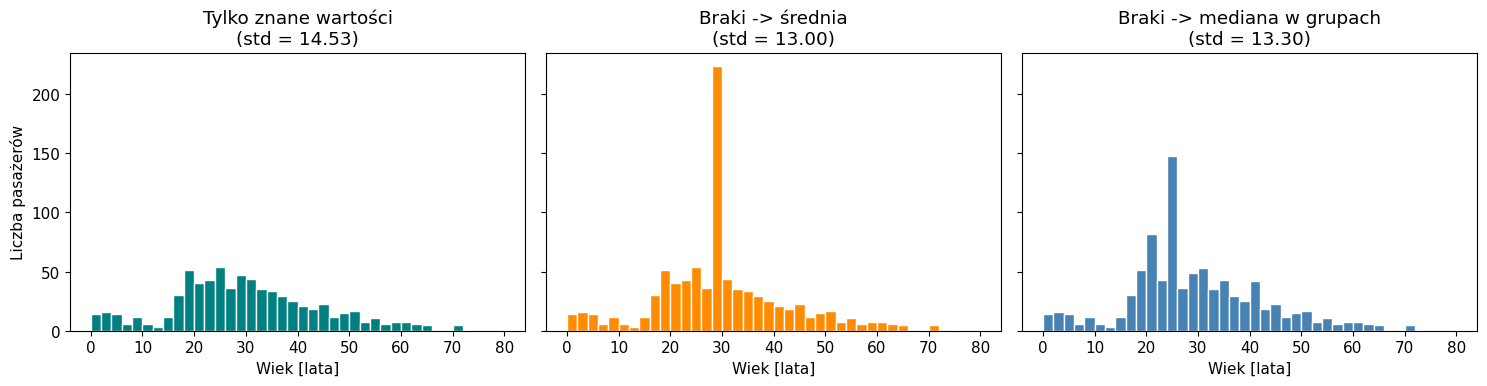

In [22]:
titanic["Age_brak"] = titanic["Age"].isna()

wiek_srednia = titanic["Age"].fillna(titanic["Age"].mean())
mediana_grupy = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
wiek_grupy = titanic["Age"].fillna(mediana_grupy)

std_oryg = titanic["Age"].dropna().std()
std_srednia = wiek_srednia.std()
std_grupy = wiek_grupy.std()

print(f"Oryginalne odch. std.: {std_oryg:.2f}")
print(f"Średnia odch. std.: {std_srednia:.2f}")
print(f"Mediana w grupach odch. std.: {std_grupy:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.arange(0, 82, 2)

axes[0].hist(titanic["Age"].dropna(), bins=bins, color="teal", edgecolor="white")
axes[0].set_title(f"Tylko znane wartości\n(std = {std_oryg:.2f})")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Liczba pasażerów")

axes[1].hist(wiek_srednia, bins=bins, color="darkorange", edgecolor="white")
axes[1].set_title(f"Braki -> średnia\n(std = {std_srednia:.2f})")
axes[1].set_xlabel("Wiek [lata]")

axes[2].hist(wiek_grupy, bins=bins, color="steelblue", edgecolor="white")
axes[2].set_title(f"Braki -> mediana w grupach\n(std = {std_grupy:.2f})")
axes[2].set_xlabel("Wiek [lata]")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Najbardziej zniekształca braki średniej. Najbardziej nienaturalny pik w okolicy 30 lat. odchylanie jest różne od znanych wartości aż o 1.5. W przypadku mediany w grupach wartości są rozbijane na ilka mniejszych słupków, ale nie już aż tak z takimi pikiem w góre.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

IterativeImputer odch. std.: 13.64


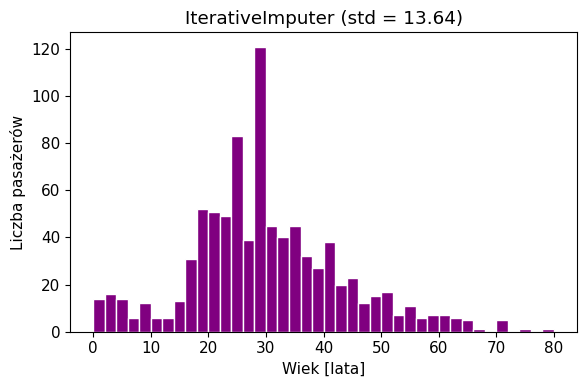

In [23]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

dane_imputacja = titanic[["Pclass", "SibSp", "Parch", "Fare", "Age"]].copy()
dane_imputacja["Sex_Male"] = (titanic["Sex"] == "male").astype(int)

imputer = IterativeImputer(random_state=42)
dane_zainputowane = imputer.fit_transform(dane_imputacja)
wiek_model = pd.Series(dane_zainputowane[:, 4], index=titanic.index)

std_model = wiek_model.std()
print(f"IterativeImputer odch. std.: {std_model:.2f}")

plt.figure(figsize=(6, 4))
plt.hist(wiek_model, bins=np.arange(0, 82, 2), color="purple", edgecolor="white")
plt.title(f"IterativeImputer (std = {std_model:.2f})")
plt.xlabel("Wiek [lata]")
plt.ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

Porównując z zadaniem 5 IterativeImputer daje najlepsze wyniki. Najmniej spośród pozostałych spadło odchyllenie standardowe. Nie ma też szcztucznego skupienia się na jednym piku.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [33]:
mieszkania = pd.read_csv("nieruchomosci.csv")
print(mieszkania.dtypes)
print(mieszkania.isna().sum())
print(mieszkania["powierzchnia"].unique())

id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']


*Twoja odpowiedź:* Pandas widzi 4 braki w powierzchni oraz 4 braki w roku budowy. Powierzchnia dostała typ object ponieważ zawiera string "brak".

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [34]:
for kolumna in mieszkania.columns:
    print(kolumna, mieszkania[kolumna].unique())

id [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]
miasto ['Warszawa' 'Kraków' 'Wrocław' 'Poznań' 'Gdańsk']
dzielnica ['Mokotów' 'Krowodrza' 'Krzyki' 'Grunwald' 'Wrzeszcz' 'Śródmieście'
 'Podgórze' 'Stare Miasto' 'Jeżyce' 'Oliwa' 'Żoliborz' 'Kazimierz'
 'Psie Pole' 'Rataje' 'Siedlce' 'Praga' 'Nowa Huta' 'Fabryczna' 'Wilda'
 'Przymorze' 'Ochota' 'Bronowice' 'Centrum' 'Ursynów' 'Dębniki' 'Zaspa'
 'Wilanów' 'Łagiewniki' 'Biskupin' 'Sołacz' 'Chełm' 'Bielany' 'Ruczaj'
 'Gaj' 'Główna' 'Morena' 'Targówek' 'Mistrzejowice' 'Ołbin' 'Piątkowo'
 'Suchanino']
powierzchnia ['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']
liczba_pokoi [3 2 4 1 5]
rok_budowy ['2015' nan '2010' '2018' '1998' '2020' '2005' '2019' 'brak' '2001' '2016'
 '1995' '2012' '2017' '2014' '2008' '2011' '1999' '2003' '2013' '2009

*Twoja odpowiedź:* Dla powierzchni 0 oznacza brak, natomiast dla pientra już może to oznaczać, że jest to na przykład parter.

In [35]:
braki_slownik = {
    "powierzchnia": ["brak", "0", 0],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999", -999],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": [-1, -999]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
print(mieszkania.dtypes)
print(mieszkania.isna().sum())

id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [37]:
print(mieszkania["stan"].value_counts(dropna=False))
mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Deweloperski"})
print(mieszkania["stan"].value_counts(dropna=False))

stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


W stanie wkradł się chiński znaczek, wartość została zamieniona na bardziej pasującą.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

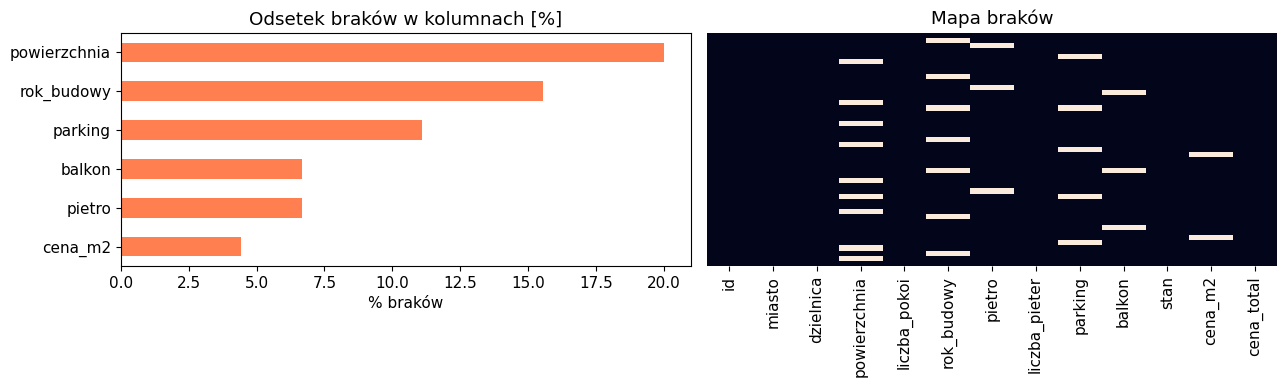

              powierzchnia  rok_budowy    pietro       parking    balkon  \
powierzchnia  1.000000e+00   -0.214599 -0.133631 -4.170558e-17 -0.133631   
rok_budowy   -2.145988e-01    1.000000 -0.114708  4.335550e-02  0.131095   
pietro       -1.336306e-01   -0.114708  1.000000 -9.449112e-02 -0.071429   
parking      -4.170558e-17    0.043355 -0.094491  1.000000e+00 -0.094491   
balkon       -1.336306e-01    0.131095 -0.071429 -9.449112e-02  1.000000   
cena_m2      -1.078328e-01   -0.092563 -0.057639 -7.624929e-02 -0.057639   

               cena_m2  
powierzchnia -0.107833  
rok_budowy   -0.092563  
pietro       -0.057639  
parking      -0.076249  
balkon       -0.057639  
cena_m2       1.000000  


In [38]:
braki_kolumn = mieszkania.isna().mean() * 100
braki_kolumn = braki_kolumn[braki_kolumn > 0].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

braki_kolumn.plot.barh(ax=axes[0], color="coral")
axes[0].set_title("Odsetek braków w kolumnach [%]")
axes[0].set_xlabel("% braków")

sns.heatmap(mieszkania.isna(), cbar=False, ax=axes[1], yticklabels=False)
axes[1].set_title("Mapa braków")

plt.tight_layout()
plt.show()

kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()].tolist()
macierz_korelacji = mieszkania[kolumny_z_brakami].isna().corr()
print(macierz_korelacji)

*Twoja odpowiedź:* Braki nie znajdują się w tych samych wierszach, znajdują się pojedyńczo z różnym rozstawem.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [39]:
poprawne = mieszkania.dropna(subset=["powierzchnia", "cena_m2", "cena_total"])
zgodnosc = np.isclose(poprawne["cena_total"], poprawne["powierzchnia"] * poprawne["cena_m2"]).all()
print(zgodnosc)

braki_pow_przed = mieszkania["powierzchnia"].isna().sum()
braki_cena_przed = mieszkania["cena_m2"].isna().sum()

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(mieszkania["cena_total"] / mieszkania["powierzchnia"])

braki_pow_po = mieszkania["powierzchnia"].isna().sum()
braki_cena_po = mieszkania["cena_m2"].isna().sum()

print(f"Usunięte braki powierzchnia: {braki_pow_przed - braki_pow_po}")
print(f"Usunięte braki cena_m2: {braki_cena_przed - braki_cena_po}")

True
Usunięte braki powierzchnia: 9
Usunięte braki cena_m2: 2


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [40]:
mieszkania["rok_budowy_brak"] = mieszkania["rok_budowy"].isna()
mieszkania["pietro_brak"] = mieszkania["pietro"].isna()
mieszkania["parking_brak"] = mieszkania["parking"].isna()
mieszkania["balkon_brak"] = mieszkania["balkon"].isna()

print(mieszkania.groupby("miasto")["rok_budowy"].median())
print(mieszkania.groupby("stan")["rok_budowy"].median())

mediana_rok_stan = mieszkania.groupby("stan")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_rok_stan)

mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)

mieszkania["parking"] = mieszkania["parking"].fillna("Nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("Nieznane")

print(mieszkania.isna().sum().sum())

miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

       powierzchnia   rok_budowy       cena_m2
count     36.000000    38.000000     43.000000
mean      64.638889  2010.289474  10223.255814
std       13.684512     7.828941   1611.689030
min       42.000000  1995.000000   8200.000000
25%       54.750000  2004.250000   9000.000000
50%       63.000000  2011.500000   9800.000000
75%       72.750000  2016.750000  11100.000000
max       95.000000  2022.000000  15000.000000
       powierzchnia   rok_budowy       cena_m2
count     45.000000    45.000000     45.000000
mean      64.933333  2010.644444  10244.336043
std       12.755391     7.407476   1623.857997
min       42.000000  1995.000000   8200.000000
25%       56.000000  2006.000000   9000.000000
50%       62.000000  2011.000000   9800.000000
75%       72.000000  2017.000000  11200.000000
max       95.000000  2022.000000  15000.000000


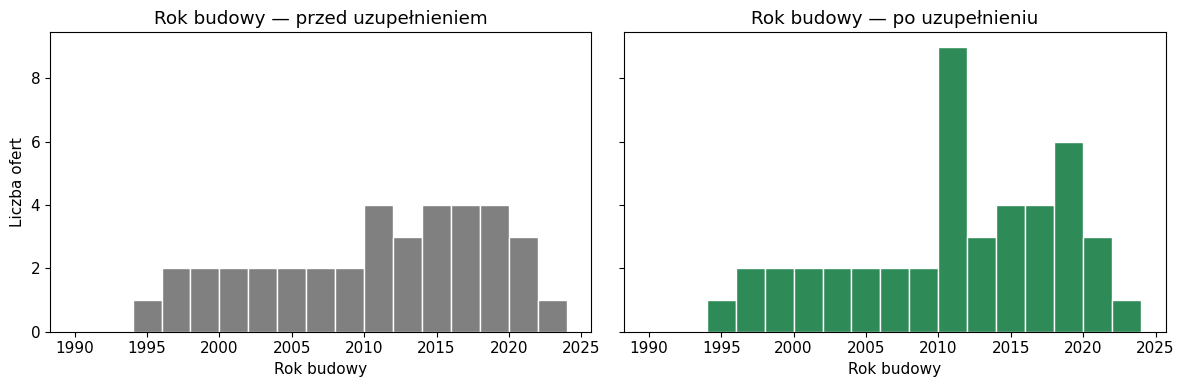

In [41]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

kolumny_porownanie = ["powierzchnia", "rok_budowy", "cena_m2"]
print(surowe[kolumny_porownanie].describe())
print(mieszkania[kolumny_porownanie].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins_rok = np.arange(1990, 2026, 2)

axes[0].hist(surowe["rok_budowy"].dropna(), bins=bins_rok, color="gray", edgecolor="white")
axes[0].set_title("Rok budowy — przed uzupełnieniem")
axes[0].set_xlabel("Rok budowy")
axes[0].set_ylabel("Liczba ofert")

axes[1].hist(mieszkania["rok_budowy"], bins=bins_rok, color="seagreen", edgecolor="white")
axes[1].set_title("Rok budowy — po uzupełnieniu")
axes[1].set_xlabel("Rok budowy")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Po uzupełnieniu widać większy pik w roku budowy po 2010 i w okolicach 2020. Reszta pozostała bez zmian.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` |brak,0,Nan |6 |cena_total / cena_m2 | Naturalnie powierzchnia musi wyjsc dzielac cene przez cene za metr |
| `cena_m2` |-1, -999 |2 |cena_total / powierzchnia | Matematycznie wyjdzie logicznie.|
| `rok_budowy` |brak, NaN |6 | Flaga i uzupełnienie medianą według stanu | Po stanie mieszkania można mniej więcej określić jego rok budowy.|
| `pietro` | brak, -999 |3 |Flaga i liczba_pieter // 2 | Neutralnie, najwieksze prawdopodobienstwo, ze sa one na srodku. |
| `parking` | ? |4 | flaga i zmiana na nieznane| Ciężko określić czy ma parking czy nie, więc zamiana.|
| `balkon` |? | 2 |flaga i zmiana na nieznane |Ciężko określić czy ma balkon czy nie, więc zamiana |
| `stan` | chińskie znaczki | 1 | zmiana na stan deweloperski pasujący do kategorii | ujednolicenie|

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [42]:
dane_baza = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
dane_baza["cena_m2"] = dane_baza["cena_m2"].fillna(dane_baza["cena_total"] / dane_baza["powierzchnia"])
dane_baza["stan"] = dane_baza["stan"].replace({"很好": "Bardzo dobry"})

kompletne = dane_baza.dropna(subset=["rok_budowy", "cena_m2"])
corr_bazowa = kompletne["rok_budowy"].corr(kompletne["cena_m2"])

wariant_global = dane_baza["rok_budowy"].fillna(dane_baza["rok_budowy"].median())
corr_global = wariant_global.corr(dane_baza["cena_m2"])

mediana_miasto = dane_baza.groupby("miasto")["rok_budowy"].transform("median")
wariant_miasto = dane_baza["rok_budowy"].fillna(mediana_miasto)
corr_miasto = wariant_miasto.corr(dane_baza["cena_m2"])

mediana_stan = dane_baza.groupby("stan")["rok_budowy"].transform("median")
wariant_stan = dane_baza["rok_budowy"].fillna(mediana_stan)
corr_stan = wariant_stan.corr(dane_baza["cena_m2"])

print(f"Korelacja bez braków: {corr_bazowa:.4f}")
print(f"Mediana całościowa:   {corr_global:.4f} (różnica: {abs(corr_global - corr_bazowa):.4f})")
print(f"Mediana wg miasta:    {corr_miasto:.4f} (różnica: {abs(corr_miasto - corr_bazowa):.4f})")
print(f"Mediana wg stanu:     {corr_stan:.4f} (różnica: {abs(corr_stan - corr_bazowa):.4f})")

Korelacja bez braków: 0.7087
Mediana całościowa:   0.6779 (różnica: 0.0308)
Mediana wg miasta:    0.7101 (różnica: 0.0014)
Mediana wg stanu:     0.6973 (różnica: 0.0114)


*Twoja odpowiedź:* Najmniej zmienia korelację Mediana wg miasta.